# How to use the minimum bias heavy ion format (**HION14**)
The minimum bias release of ***ATLAS*** *Open Data* consists of data collected with minimum bias triggers during Pb-Pb collisions in Run 2 of the LHC at ATLAS. For the minimum bias trigger to fire, at least two coincident hits in the Minimimum Bias Trigger Scintillator (MBTS) systems are required. They are  therefore intended to collect an unbiased snapshot of an event in these collisions. These data are provided in the **HION14** format, which was explicitly designed to accomodate them. This format contains detailed tracking information, but does not retain most reconstructed physics objects, such as electrons and jets. It is primarily suited for investigations of the collective motion and properties of the quark-gluon plasma.

This notebook will walk you through a quick example of using these data via `uproot` and demonstrate how they can to be used to reconstruct the centrality limits used in ATLAS heavy-ion analyses.

First, we need to setup our Python interface, `atlasopenmagic`, for using these data.

In [83]:
# Install atlasopenmagic. --user is only required on SWAN, but shouldn't cause issues elsewhere.
%pip install --user atlasopenmagic

ERROR: Can not perform a '--user' install. User site-packages are not visible in this virtualenv.
Note: you may need to restart the kernel to use updated packages.


The package also comes withs a list of useful packages which we can install and then import.

In [84]:
# SWAN does not include the local package installation in the PYTHONPATH, so we work around this.
# Again, this shouldn't cause issues elsewhere.
import sys
import os
sys.path += [ f'{os.environ["HOME"]}/.local/lib/python{sys.version_info.major}.{sys.version_info.minor}/site-packages' ]

# We can now safely import atlasopenmagic and install its recommended packages
import atlasopenmagic
atlasopenmagic.install_from_environment()

Installing packages: ['aiohttp>=3.9.5', 'atlasopenmagic>=1.9.0', 'awkward>=2.6.7', 'awkward-pandas>=2023.8.0', 'coffea~=0.7.0', 'fsspec>=2025.7.0', 'hist>=2.8.0', 'ipykernel>=6.29.5', 'jupyter>=1.0.0', 'lmfit>=1.3.2', 'matplotlib>=3.9.1', 'metakernel>=0.30.2', 'notebook<7', 'numpy>=1.26.4', 'pandas>=2.2.2', 'papermill>=2.6.0', 'pip>=24.2', 'scikit-learn>=1.5.1', 'uproot>=5.3.10', 'uproot3>=3.14.4', 'fsspec-xrootd>=0.5.1', 'jupyterlab_latex~=3.1.0', 'vector>=1.4.1']


  Using cached coffea-0.7.31-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached ipykernel-7.4.0-py3-none-any.whl.metadata (3.4 kB)
  Using cached coffea-0.7.30-py2.py3-none-any.whl.metadata (9.6 kB)
INFO: pip is looking at multiple versions of coffea to determine which version is compatible with other requirements. This could take a while.
  Using cached coffea-0.7.29-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached coffea-0.7.28-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached coffea-0.7.27-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached coffea-0.7.26-py2.py3-none-any.whl.metadata (9.6 kB)
  Using cached coffea-0.7.25-py2.py3-none-any.whl.metadata (9.5 kB)
  Using cached coffea-0.7.24-py2.py3-none-any.whl.metadata (9.5 kB)
INFO: pip is still looking at multiple versions of coffea to determine which version is compatible with other requirements. This could take a while.
  Using cached coffea-0.7.23-py2.py3-none-any.whl.metadata (9.5 kB)
  Using cached coffea-0.7.22-p

Installation complete. You may need to restart your Python environment for changes to take effect.


In [85]:
# File reading libraries
import uproot
import atlasopenmagic as atom
# Analysis libraries
import awkward as ak
import numpy as np
# Utility libraries
import matplotlib.pyplot as plt
import matplotlib
# Change our plotting font to sans serif, for aesthetics!
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica","Arial","Nimbus Sans","DejaVu Sans"],
    "svg.fonttype": "path"
})
from tqdm import tqdm
import time

These functions will help us make our plots look pretty later on, don't pay them too much mind!

In [86]:
# - Useful plotting functions - #
# Use innerward facing ticks in all direction
def inner_ticks(ax:matplotlib.axes.Axes):
    ax.tick_params(direction="in",which="both",top=True,right=True)

# Plot an ATLAS Open Data label on a pair of axes
def atlas_label(ax:matplotlib.axes.Axes,loc="upper right",text="Open Data",fontsize=16,pos_ovr=None,msg=""):
    locs = {
        "upper left" : (.04, .88),
        "upper right": (.96, .88),
    }
    if (pos_ovr is not None) and isinstance(pos_ovr,tuple):
        pos = pos_ovr 
    else: pos = locs[loc]
    align = ("left","right","center"); ha = "left"
    for a in align:
        if a in loc: ha = a
    ax.text(
        *pos,r"$\mathbfit{ATLAS}$ "+text,
        transform=ax.transAxes,fontsize=fontsize,ha=ha,va="bottom"
    )
    if msg:
        ax.text(
            pos[0], pos[1]-.05, msg,
            transform=ax.transAxes, fontsize=fontsize*.75, ha=ha, va="bottom"
        )

## Accessing the data with `atlasopenmagic`

In order to access the minimum bias data, we have to switch our `atom` release over to their release, `2024r-hi`. We can also check the available dataset IDs (DSIDs) through the `available_datasets()` method.

In [87]:
# Fetch minimum bias heavy ion collision data
atom.set_release("2024r-hi")
dsids = atom.available_datasets()
print(f'Available DSIDs: {dsids}')

Release '2024r-hi' already active with cached metadata.
Active release: 2024r-hi. (Datasets path: REMOTE)


Available DSIDs: ['420000', 'data']


Notice that we only have two DSIDs available in the minimum bias release. One is for our collision data (`data`), and the second is for a Monte Carlo sample (`420000`). Let's see if we can figure out what this sample is with the `get_metadata()` method.

In [88]:
metadata = atom.get_metadata('420000')
for md in metadata:
    print(f'{md:>25} : {metadata[md]}')


           dataset_number : 420000
            physics_short : Hijing_PbPb_5p02TeV_MinBias_Flow_JJFV6
                    e_tag : e4962
         cross_section_pb : None
               genFiltEff : 1.0
                  kFactor : 1.0
                  nEvents : 100000
             sumOfWeights : 100000.0
      sumOfWeightsSquared : 100000.0
                  process : Minimum bias
                generator : Hijing 1.383bs.2
                 keywords : ['minBias']
              description : Pb + Pb collisions at 5020 GeV/(colliding nucleon pair) using function jjia_minbias_new
                 job_path : https://gitlab.cern.ch/atlas-physics/pmg/infrastructure/mc15joboptions/-/blob/master/share/DSID420xxx/MC15.420000.Hijing_PbPb_5p02TeV_MinBias_Flow_JJFV6.py
                CoMEnergy : 5000.0
                GenEvents : 100000
                  GenTune : Hijing
                      PDF : jjia_minbias_new
                  Release : Athena_25.0.19,e4962_a882_r11176_p6480
               

We can see that this sample of 100,000 events simulates the collective flow of the quark-gluon plasma!

For this demonstration, though, we don't need any Monte Carlo samples. We will only be using the collision data files.

In [89]:
sample_defs = {
    "Data": {'dids': ["data"], 'color': 'red'}
}
data_samples = atom.build_dataset(sample_defs,skim="noskim",protocol="root",cache=False)

## Reading the **HION14** format with `uproot`

Let's start by just opening a file and viewing its structure. We'll open the very first file in our dataset and view the TTree objects that it contains.

In [90]:
# Take the very first file in our dataset
filename = data_samples['Data']['list'][0]
print("TTree objects inside the ROOT file:")
for key in uproot.open(filename).keys():
    print("-",key)

TTree objects inside the ROOT file:
- ##Params;2
- ##Params;1
- ##Shapes;2
- ##Shapes;1
- ##Links;2
- ##Links;1
- CollectionTree;1
- POOLContainer;1
- POOLContainerForm;1
- POOLCollectionTree;1
- MetaData;1
- MetaDataHdr;1
- MetaDataHdrForm;1


Your analysis variables will be stored in `CollectionTree`; let's open this and view some of the branches available to us. You can also view the [full, documented list](https://atlas-physlite-content-opendata.web.cern.ch/#page2) of branches.

In [91]:
with uproot.open({filename: 'CollectionTree'}) as tree:
    first_ten_branches = list(tree.keys())[:10]
    tree.show(filter_name=first_ten_branches, name_width=50, typename_width=50, interpretation_width=50)

name                                               | typename                                           | interpretation                                    
---------------------------------------------------+----------------------------------------------------+---------------------------------------------------
xTrigDecisionAux.                                  | xAOD::TrigDecisionAuxInfo_v1                       | AsObjects(Model_xAOD_3a3a_TrigDecisionAuxInfo_5...
EventInfoAux.                                      | xAOD::AuxInfoBase                                  | AsStridedObjects(Model_xAOD_3a3a_AuxInfoBase_v1)
CaloSumsAux.                                       | xAOD::AuxContainerBase                             | AsStridedObjects(Model_xAOD_3a3a_AuxContainerBa...
CombinedMuonTrackParticlesAux.                     | xAOD::AuxContainerBase                             | AsStridedObjects(Model_xAOD_3a3a_AuxContainerBa...
ExtrapolatedMuonTrackParticlesAux.                 | xAOD::A

Our track variables are stored in the `InDetTrackParticlesAux` container. For example, let's read the charge-momentum ratios of our tracks, convert them into the track momentum by taking the absolute reciprocal, and plot the distribution.

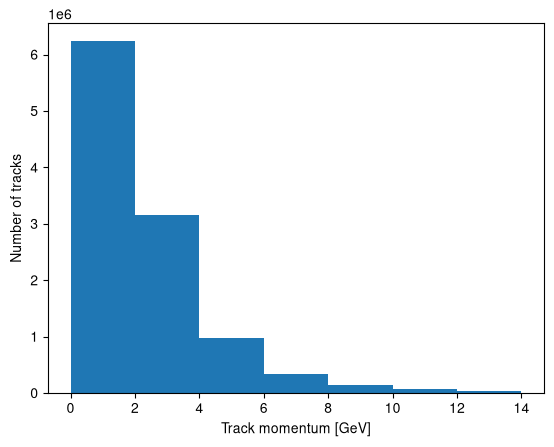

In [92]:
with uproot.open({filename: 'CollectionTree'}) as tree:
    track_qop = tree['InDetTrackParticlesAuxDyn.qOverP'].array()
    # Flatten the array to remove jagged structure
    track_qop = ak.flatten(track_qop)

    # Complete the track momentum
    track_p = np.abs(1/track_qop)

    # Plot track momentum in GeV
    fig, ax = plt.subplots()
    ax.hist(track_p*1e-3, range=(0, 14), bins=7)
    ax.set_ylabel('Number of tracks')
    ax.set_xlabel(r'Track momentum [GeV]')

## Determining the centrality of minimum bias events

In ATLAS, centrality limits are defined by Forward Calorimeter (FCal) measurements. Specifically, we measure the transverse energy deposited in these calorimeters, which will correlate to the hard-scattering rate in the event.

We will be iterating over data files to a transverse energy histogram, so we define that histogram now.

In [93]:
# Histogram parameters for the FCal total transverse energy histogram which we want to fill
h_def = {
    "bin_width": 20e3, # MeV
    "range": (0,5e6) # MeV
}
h_def["n_bins"] = int((h_def["range"][1] - h_def["range"][0]) / h_def["bin_width"])
# Initialise an empty total ET histogram
h_total_eT, h_def["bin_edges"] = np.histogram([-1],h_def["n_bins"],h_def["range"])

> **Note:** Although the FCal transverse energy is TeV-scale, the energy in our files will be stored in MeV; pay attention to your units!

We now define a function to read a file and make a histogram which we will then add to our total histogram. In ATLAS, FCals are positioned in two different pseudo-rapidity ranges, one in positive $\eta$ and the other in negative $\eta$. We label these positive and negative regions as 'A' side and 'C' side, respectively. On order to get the total transverse energies, we read the transverse energies deposited in each side and sum them. Them, we bin our total value according to the histogram we have already defined. In this cell we also define a little function to convert a `numpy` histogram into a sparkline: this is purely aesthetic whilst we wait for our data to process!

In [94]:
# Take a url and grab the total transverse energy histogram from its ROOT file
# Using XRootDSource as our handler helps mitigate vector read errors when streaming our data
from uproot.source.xrootd import XRootDSource
def grab_hist_from_file(url:str)->np.ndarray:
    with uproot.open(f"{url}:CollectionTree", handler=XRootDSource) as tree:
        fcal = ak.zip({
        branch.split(".")[1]: tree[branch].array() for branch in (
            f"EventInfoAuxDyn.FCalEt{x}" for x in ("A","C")
        )})
        fcal["TotalEt"] = fcal["FCalEtA"] + fcal["FCalEtC"]
        this_hist,_ = np.histogram(fcal["TotalEt"],bins=h_def["n_bins"],range=h_def["range"])
    return this_hist

# Converts a numpy histogram into a sparkline histogram
# Allows us to watch our histogram fill in real time!
blocks = " ▁▂▃▄▅▆▇█"
def to_sparkline(hist:np.ndarray,lim=20)->str:
    if len(hist) > lim: # Trim the histogram if it is too large, taking evenly-spaced bins along it
        hist = np.array([hist[int( (len(hist)-1)*i/lim )] for i in range(lim)])
    if np.max(hist)==0:
        return blocks[0]*len(hist)
    norm = hist / np.max(hist)
    return f'{"".join(blocks[int(v * (len(blocks) - 1))] for v in norm)} Events: {int(np.sum(hist))}'

Now, we process a subset of our data, since running over the full dataset could take a long time! 

In [95]:
start = time.time()
print(f'Total number of files: {len(data_samples["Data"]["list"])}')
print("Processing a subset of files...")
pbar = tqdm(data_samples["Data"]["list"][:25],desc=to_sparkline(h_total_eT))
for url in pbar:
    h_total_eT = h_total_eT + grab_hist_from_file(url)
    # Update progress bar histogram
    pbar.set_description(to_sparkline(h_total_eT))
end = time.time()
print(f"Total time: {round((end - start) / 60, 1)} mins")

Total number of files: 1913
Processing a subset of files...


█                    Events: 266234: 100%|██████████| 25/25 [01:21<00:00,  3.26s/it]

Total time: 1.4 mins


Now we have our histogram of the total transverse energy, `h_total_eT`, we can plot it and infer our centrality ranges! We do this in a number of steps:

First, in order to make our distribution independent of the binning we choose, we make it a differential by diving by the bin width. Then, we take the calculate percentiles for our total transverse energy distribution by finding percentiles from the cumulative sum.

In [96]:
TeV = 1e-6
# Calculate the differential histogram by diving by the bin width
h_diff = h_total_eT / h_def["bin_width"]

# Flip our histogram and take its cumulative sum (mirror its x-axis)
# Then, normalise this
# Doing so will produce an array from 0. -> 1. with high centrality collisions at the beginning
norm_cum_int = np.cumsum(np.flip(h_total_eT[h_total_eT!=0])) / np.sum(h_total_eT)

# Define centrality ranges
centrality_ranges = {
    40: "40 - 100%",
    20: "20 - 40%",
    10: "10 - 20%",
    0: "0 - 10%"
}
labels = [
    "(40 - 100)%",
    "(20 - 40)%",
    "(10 - 20)%",
    "(0 - 10)%"
]
# Set the index of the first centrality range to be zero
centrality_ix = [0]
# Then calculate the other indices of the centrality ranges by finding the index closest to the centrality,
# e.g. closest index to .02 for the start of the 20 - 40% range.
centrality_ix += [np.argmin(np.abs(np.flip(norm_cum_int) - c*.01)) for c in centrality_ranges]

# Print the values of transverse energy which our centrality ranges correspond to
for i, label in enumerate(labels):
    print(f'{label:>12} : ({h_def["bin_edges"][centrality_ix[i]]*TeV:.2f} - {h_def["bin_edges"][centrality_ix[i+1]]*TeV:.2f}) TeV')

 (40 - 100)% : (0.00 - 0.70) TeV
  (20 - 40)% : (0.70 - 1.88) TeV
  (10 - 20)% : (1.88 - 2.86) TeV
   (0 - 10)% : (2.86 - 4.92) TeV


Let's compare to these to [published ATLAS](https://arxiv.org/abs/2206.12594) centrality ranges:

| Centrality [%] | FCal $E_\mathrm{T}$ range |
| --- | --- |
| 40 - 100 | < 0.875 |
| 20 - 40  | 0.875 - 2.05 |
| 10 - 20  | 2.05 - 2.99 |
| 0 - 10   | > 2.99 |

(Based on Table 1)

You can already see that we are in the right ballpark, even with only twenty-five files processed!


We can also plot our differential distribution to produce a [familiar curve](https://arxiv.org/abs/1808.03951) in log space, and also visualise our centrality bands on this curve!

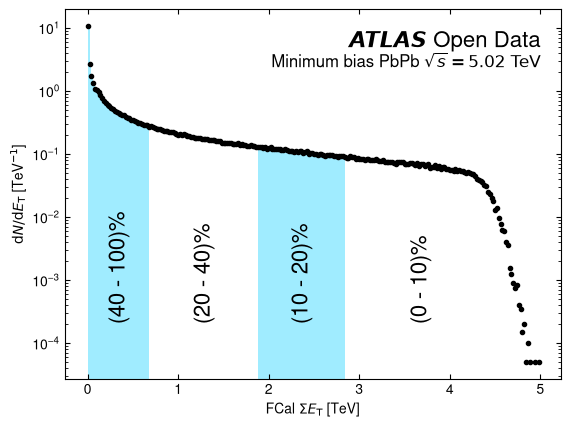

In [97]:
fig, ax = plt.subplots()
# Iterate over the centrality ranges and fill histograms in their ranges.
# This approximates filling the areas under the curves.
for i,col in zip(range(len(centrality_ranges)),("#2cd5ff73","white","#2cd5ff73","white")):
    ixmin, ixmax = centrality_ix[i], centrality_ix[i+1]
    ax.stairs(h_diff[centrality_ix[i]:centrality_ix[i+1]-1],h_def["bin_edges"][ixmin:ixmax]*TeV,fill=True,color=col)

    A = .5 if labels[i]!="(0 - 10)%" else .4
    ax.text((h_def["bin_edges"][ixmin]+(h_def["bin_edges"][ixmax]-h_def["bin_edges"][ixmin])*A)*TeV,20e-5,labels[i],rotation=90,fontsize=16,ha="center",va="bottom")
ax.scatter(h_def["bin_edges"][:-1]*TeV,h_diff,color="black",marker=".")

ax.set_yscale("log")
atlas_label(ax,msg=r"Minimum bias PbPb $\sqrt{s}=5.02\ \mathrm{TeV}$")
inner_ticks(ax)
ax.set_xlabel(r"FCal $\Sigma E_\mathrm{T}$ [TeV]"); ax.set_ylabel(r"$\mathrm{d}N/\mathrm{d}E_{\mathrm{T}}$ [TeV$^{-1}$]")
_ = ''

Now that you are familiar with reading and manipulating data with **HION14** format, we look forward to seeing the analyses you undertook with these data!

## Producing analysis NTuples from **HION14**
Whilst the **HION14** format has been designed to be as light-weight as possible, the files are still large and run-time can be throttled by network downlad speeds. In some cases, an effective solution may be to produce local, smaller-scale NTuples for use in your analysis. We would recommend using a C++ NTuple framework for this. For example, you may follow the instructions in [Writing NTuples and Trees using the Text Configuration](https://atlas-software.docs.cern.ch/analysis/analysis_tutorial/AnalysisSWTutorial/cpalg_ntuple/) from the [ATLAS Analysis Software Tutorial](https://atlas-software.docs.cern.ch/analysis/).